# 02 — GSE13159 (MILE) veri seti ve iki veri setinin karşılaştırılması
Bu defter `src/eda_gse13159.py` ve `src/plot_gse_qc.py` betiklerini bölüm bölüm çalıştırır; kod betiklerle birebir aynıdır.

**Not:** GEO seri matrisi yaklaşık 886 MB'tır; indirme ve alt küme oluşturma birkaç dakika sürer.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pervinncelikk/ML-ALL-AML-PROJECT/blob/main/notebooks/02_gse13159_eda_karsilastirma.ipynb)

In [ ]:
import os
if not os.path.exists('/content/ML-ALL-AML-PROJECT'):
    !git clone -q https://github.com/pervinncelikk/ML-ALL-AML-PROJECT.git /content/ML-ALL-AML-PROJECT
!pip install -q -r /content/ML-ALL-AML-PROJECT/requirements.txt
os.kill(os.getpid(), 9)  # oturumu yeniden başlat

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.5 which is incompatible.
pytensor 2.38.3 requires numba<=0.65.1,>=0.58, but you have numba 0.68.1 which is incompatible.


### Çalışma dizini ve veri

In [1]:
import os, sys
os.chdir('/content/ML-ALL-AML-PROJECT')
sys.path.insert(0, 'src')
!python scripts/download_data.py --golub --gse
!python src/data_gse13159.py  # ALL/AML alt kümesini oluşturur

Kaggle API ile indirildi
indiriliyor: https://raw.githubusercontent.com/cran/hddplot/master/data/golubInfo.rda
data_set_ALL_AML_train.csv 8391cdcbc4d7d8618a0587ff92fa4d80
data_set_ALL_AML_independent.csv 4b4f0dfc941b0662594e8848ec2d8b06
actual.csv b8d0bd345a4c32fbd81629924cffe804
indiriliyor: https://ftp.ncbi.nlm.nih.gov/geo/series/GSE13nnn/GSE13159/matrix/GSE13159_series_matrix.txt.gz
indiriliyor: https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPLnnn/GPL570/annot/GPL570.annot.gz
indiriliyor: https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPLnnn/GPL80/annot/GPL80.annot.gz
{
 "n_total_samples": 2096,
 "n_probes": 54675,
 "platform": [
  "GPL570"
 ],
 "processing": [
  "Data pre-processing included a summarization and quantile normalization step to generate probe set level signal intensities for each microarray experiment and was performed as previously published by Liu WM et al. PQN and DQN: algorithms for expression microarrays. J.Theor.Biol. 2006;243:273-278."
 ],
 "class_counts_all": {
  "CL

## Kütüphaneler ve ayarlar

In [2]:
"""GSE13159 (ALL vs AML alt kümesi) EDA'sı ve Golub ile karşılaştırma (Ara Rapor, A1/A3).

Çalıştırma: python src/eda_gse13159.py
Ön koşul : data/raw/gse13159/ içinde series matrix + GPL570 + GPL80 anotasyonları
Çıktılar : results/figures/{en,tr}/gse_*.pdf|png, cross_*.pdf|png,
           results/tables/gse_*.csv, cross_*.csv, gse_numbers.json
"""
import json
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests

from config import SEED, PROC, TAB, CLIP_LOW, CLIP_HIGH, FOLD_MIN, DIFF_MIN, C_ALL, C_AML, C_3, GREY
from data_golub import load_golub, preprocess_log, variation_filter
from data_gse13159 import build_subset, find, read_gpl_annotation, collapse_to_genes
from plotstyle import plt, save, T, COL_W, FULL_W

warnings.filterwarnings("ignore")
rng = np.random.default_rng(SEED)
NUM = {}
pal = {"ALL": C_ALL, "AML": C_AML}

## 1. veri
GEO GSE13159 seri matrisinden ALL (8 alt tip) ve AML (6 alt tip) örnekleri seçilir; alt küme `data/processed/` altına kaydedilir.

In [3]:
#  veri
if not (PROC / "gse13159_allaml_expr.parquet").exists():
    _, _, info = build_subset()
    json.dump(info, open(TAB / "gse_build_info.json", "w"), indent=1, default=str)
info = json.load(open(TAB / "gse_build_info.json"))
NUM["build"] = info
X = pd.read_parquet(PROC / "gse13159_allaml_expr.parquet")
meta = pd.read_csv(PROC / "gse13159_allaml_meta.csv", index_col=0).loc[X.index]
allnan = X.columns[X.isna().all()]
NUM["affx_all_nan_dropped"] = int(len(allnan)); NUM["affx_all_nan_are_affx"] = bool(pd.Index(allnan).str.startswith("AFFX").all())
X = X.drop(columns=allnan)
lab = meta.label
tissue = meta.characteristics_ch1_0.str.split(":").str[1].str.strip().map({"bone marrow": "BM", "peripheral blood": "PB"})
NUM["tissue_by_class"] = pd.crosstab(tissue, lab).to_dict()
NUM["n"], NUM["p"] = X.shape
NUM["class_counts"] = lab.value_counts().to_dict()
NUM["subtype_counts"] = meta.mile_class.value_counts().to_dict()

## 2. kalite / ölçek
Kalite ve ölçek: boş AFFX probları, 0–1 aralığı ve kantil normalizasyonun Beta(1,2; 3) dağılımıyla uyumu. Örnekler arası ortalama korelasyona IQR kuralı uygulanarak aykırı örnekler işaretlenir.

In [4]:
#  kalite / ölçek
v = X.values
NUM["nan"] = int(np.isnan(v).sum()); NUM["inf"] = int(np.isinf(v).sum())
NUM["min"], NUM["max"], NUM["median"] = float(np.nanmin(v)), float(np.nanmax(v)), float(np.nanmedian(v))
NUM["neg_or_zero_%"] = round(100 * float((v <= 0).mean()), 3)
already_log = NUM["max"] < 30   # GSE13159: DQN ile 0–1 aralığına normalize edilmiş; log alınmaz
NUM["already_log2"] = bool(already_log)
Xl = X.copy() if already_log else np.log2(X.clip(lower=1))
Xl = Xl.fillna(Xl.median())
smed = Xl.median(axis=1); siqr = Xl.quantile(.75, axis=1) - Xl.quantile(.25, axis=1)
mad = lambda s_: (s_ - s_.median()).abs().median() * 1.4826
out_med = (smed - smed.median()).abs() > 3 * mad(smed)
out_iqr = (siqr - siqr.median()).abs() > 3 * mad(siqr)
# örnekler arası korelasyon tabanlı aykırılık (en değişken 2000 prob üzerinde)
var_top = Xl.var().nlargest(2000).index
C = np.corrcoef(Xl[var_top].values)
mean_r = (C.sum(1) - 1) / (len(C) - 1)
mr = pd.Series(mean_r, index=Xl.index)
q1c, q3c = mr.quantile(.25), mr.quantile(.75)
out_cor = mr < q1c - 1.5 * (q3c - q1c)          # ders (Modül 3.2) IQR kuralı
srt = np.sort(Xl.values, axis=1)
from scipy.stats import beta as _beta
_v = np.sort(Xl.iloc[0].values); _th = _beta(1.2, 3).ppf((np.arange(1, len(_v) + 1) - .5) / len(_v))
NUM["beta_1.2_3_maxdiff"] = round(float(np.abs(_v - _th).max()), 4)
NUM["beta_1.2_3_median"] = round(float(_beta(1.2, 3).median()), 4); NUM["data_median_sample0"] = round(float(np.median(_v)), 4)
NUM["sorted_dist_max_absdiff"] = round(float(np.abs(srt - np.median(srt, axis=0)).max()), 4)   # kantil normalizasyon kontrolü
NUM["sample_median_sd"] = float(smed.std()); NUM["sample_iqr_sd"] = float(siqr.std())
NUM["mean_corr_range"] = [round(float(mr.min()), 3), round(float(mr.median()), 3)]
NUM["outlier_samples_median"] = int(out_med.sum()); NUM["outlier_samples_iqr"] = int(out_iqr.sum())
NUM["outlier_samples_corr"] = int(out_cor.sum())
NUM["outlier_samples_any"] = int((out_med | out_iqr | out_cor).sum())
NUM["sample_median_range"] = [round(float(smed.min()), 2), round(float(smed.max()), 2)]
NUM["skew_median_raw_or_log"] = round(float(np.median(stats.skew(Xl[var_top].values, axis=0))), 2)
pd.DataFrame({"label": lab, "subtype": meta.mile_class, "median_log2": smed, "iqr_log2": siqr,
              "mean_corr": mr, "outlier_any": out_med | out_iqr | out_cor}).to_csv(TAB / "gse_sample_qc.csv")

# düşük ifadeli / düşük varyanslı prob filtresi (betimsel)
expr_thr = np.percentile(Xl.values, 25)
expressed = (Xl > expr_thr).mean() >= 0.2
NUM["probes_expressed_20pct"] = int(expressed.sum())
iqr_g = Xl.quantile(.75) - Xl.quantile(.25)
NUM["probes_iqr_gt_0.5"] = int((iqr_g > .5).sum())
top5k = Xl.var().nlargest(5000).index

## 3. boyut indirgeme
Boyut indirgeme: en değişken 5.000 probla PCA, t-SNE ve UMAP.

In [5]:
# boyut indirgeme
Z = StandardScaler().fit_transform(Xl[top5k])
pca = PCA(n_components=10, random_state=SEED).fit(Z); P = pca.transform(Z)
ev = 100 * pca.explained_variance_ratio_
NUM["pca_explained_%"] = [round(x, 2) for x in ev]
NUM["pc1_vs_class_MWU_p"] = float(stats.mannwhitneyu(P[lab == "ALL", 0], P[lab == "AML", 0]).pvalue)
NUM["pc2_vs_class_MWU_p"] = float(stats.mannwhitneyu(P[lab == "ALL", 1], P[lab == "AML", 1]).pvalue)
NUM["pc1_vs_tissue_MWU_p"] = float(stats.mannwhitneyu(P[(tissue == "BM").values, 0], P[(tissue == "PB").values, 0]).pvalue)
NUM["pc2_vs_tissue_MWU_p"] = float(stats.mannwhitneyu(P[(tissue == "BM").values, 1], P[(tissue == "PB").values, 1]).pvalue)
NUM["median_vs_tissue_MWU_p"] = float(stats.mannwhitneyu(smed[tissue == "BM"], smed[tissue == "PB"]).pvalue)
# sınıf içinde doku farkı gösteren gen oranı (yalnız betimsel)
for c_ in ("ALL", "AML"):
    A_ = Xl.loc[(lab == c_) & (tissue == "BM"), top5k]; B_ = Xl.loc[(lab == c_) & (tissue == "PB"), top5k]
    pt_ = stats.ttest_ind(A_, B_, equal_var=False).pvalue
    NUM[f"tissue_DE_{c_}_fdr05_top5k"] = int((multipletests(pt_, method="fdr_bh")[1] < .05).sum())
from sklearn.metrics import silhouette_score
NUM["silhouette_pc12_class"] = round(float(silhouette_score(P[:, :2], lab)), 3)
tsne = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca").fit_transform(P)
import umap
um = umap.UMAP(n_neighbors=15, min_dist=.3, random_state=SEED).fit_transform(Z)
is_T = meta.mile_class.str.contains("T-ALL").values

## 4. ayırt edici genler
Ayırt edici problar (ALL ve AML arası testler, FDR) ve doku (kemik iliği / periferik kan) etkisi.

In [6]:
#  ayırt edici genler
a, b = Xl[lab == "ALL"], Xl[lab == "AML"]
t, p = stats.ttest_ind(b, a, equal_var=False)
lfc = b.mean() - a.mean()
de = pd.DataFrame({"log2FC_AML_vs_ALL": lfc, "welch_t": t, "p": p,
                   "fdr": multipletests(np.nan_to_num(p, nan=1), method="fdr_bh")[1]}, index=Xl.columns)
gpl570 = find("GPL570*")
p2s570 = read_gpl_annotation(gpl570) if gpl570 else pd.Series(dtype=str)
de["symbol"] = p2s570.reindex(de.index)
de = de.reindex(de.welch_t.abs().sort_values(ascending=False).index)  # |t| sırası (çok sayıda p=0 eşitliği nedeniyle p ile sıralanmaz)
de.to_csv(TAB / "gse_de.csv")
NUM["de_fdr05"] = int((de.fdr < .05).sum()); NUM["de_fdr05_absLFC1"] = int(((de.fdr < .05) & (de.log2FC_AML_vs_ALL.abs() > 1)).sum())
NUM["top10"] = de.symbol.fillna(pd.Series(de.index, index=de.index)).head(10).tolist()
top50 = de.index[:50]
# ısı haritası: sembolü olan problardan her gen için en yüksek |t|'li prob, ilk 30 gen
_u = de[de.symbol.notna()].drop_duplicates("symbol")
top30 = _u.index[:30]
NUM["heatmap_top30_genes"] = _u.symbol.iloc[:30].tolist()

## 5. Golub ile uyumlaştırma
Golub ile uyumlaştırma: problar GPL80 ve GPL570 anotasyonlarıyla gen sembollerine eşlenir, ortak genler bulunur; iki veri setinin ölçekleri, ortak PCA ve sınıf etkilerinin uyumu karşılaştırılır.

In [7]:
#  Golub ile uyumlaştırma
Xg, yg, sg, Cg, genes_g, _ = load_golub()
Xgl = preprocess_log(Xg, CLIP_LOW, CLIP_HIGH)
gpl80 = find("GPL80*")
if gpl80 is not None:
    p2s80 = read_gpl_annotation(gpl80)
else:   # yedek: Golub açıklamasındaki ilk kelime
    p2s80 = genes_g.description.str.split().str[0]
NUM["golub_probes_mapped"] = int(Xgl.columns.isin(p2s80.index).sum())
NUM["gse_probes_mapped"] = int(Xl.columns.isin(p2s570.index).sum())
Gg = collapse_to_genes(Xgl, p2s80); Gs = collapse_to_genes(Xl, p2s570)
common = Gg.columns.intersection(Gs.columns)
NUM["golub_genes"] = int(Gg.shape[1]); NUM["gse_genes"] = int(Gs.shape[1]); NUM["common_genes"] = int(len(common))
pd.Series(common).to_csv(TAB / "cross_common_genes.csv", index=False)
Gg, Gs = Gg[common], Gs[common]
# ortak genlerde sınıf etkisi uyumu
lfc_g = Gg[yg == 1].mean() - Gg[yg == 0].mean()
lfc_s = Gs[lab == "AML"].mean() - Gs[lab == "ALL"].mean()
NUM["lfc_corr_pearson"] = round(float(np.corrcoef(lfc_g, lfc_s)[0, 1]), 3)
NUM["lfc_corr_spearman"] = round(float(stats.spearmanr(lfc_g, lfc_s).statistic), 3)
tg = pd.Series(stats.ttest_ind(Gg[yg == 1], Gg[yg == 0], equal_var=False).statistic, index=common)
ts = pd.Series(stats.ttest_ind(Gs[lab == "AML"], Gs[lab == "ALL"], equal_var=False).statistic, index=common)
for K in (50, 100, 200):
    A_ = set(tg.abs().nlargest(K).index); B_ = set(ts.abs().nlargest(K).index)
    k = len(A_ & B_); N = len(common)
    NUM[f"top{K}_overlap"] = k
    NUM[f"top{K}_overlap_hypergeom_p"] = float(stats.hypergeom.sf(k - 1, N, K, K))
    NUM[f"top{K}_overlap_expected"] = round(K * K / N, 2)
ov = sorted(set(tg.abs().nlargest(100).index) & set(ts.abs().nlargest(100).index))
NUM["top100_overlap_genes"] = ov
# dağılım farkları
NUM["golub_common_median"] = round(float(np.median(Gg.values)), 2)
NUM["gse_common_median"] = round(float(np.median(Gs.values)), 2)
NUM["golub_common_iqr"] = round(float(np.subtract(*np.percentile(Gg.values, [75, 25]))), 2)
NUM["gse_common_iqr"] = round(float(np.subtract(*np.percentile(Gs.values, [75, 25]))), 2)
NUM["gene_mean_spearman"] = round(float(stats.spearmanr(Gg.mean(), Gs.mean()).statistic), 3)
NUM["gene_sd_spearman"] = round(float(stats.spearmanr(Gg.std(), Gs.std()).statistic), 3)
NUM["golub_common_range"] = [round(float(Gg.values.min()), 2), round(float(Gg.values.max()), 2)]
NUM["gse_common_range"] = [round(float(Gs.values.min()), 3), round(float(Gs.values.max()), 3)]
# birleşik PCA: (i) ham log2, (ii) veri seti içi z-skor
comb_raw = pd.concat([Gg, Gs]); dset = np.r_[np.zeros(len(Gg)), np.ones(len(Gs))]
ycomb = np.r_[yg.values, (lab == "AML").astype(int).values]
Zr = StandardScaler().fit_transform(comb_raw)
Pr = PCA(2, random_state=SEED).fit(Zr); Pr_s = Pr.transform(Zr)
Zw = np.vstack([StandardScaler().fit_transform(Gg), StandardScaler().fit_transform(Gs)])
Pw = PCA(2, random_state=SEED).fit(Zw); Pw_s = Pw.transform(Zw)
NUM["comb_raw_pc1_dataset_silhouette"] = round(float(silhouette_score(Pr_s, dset)), 3)
NUM["comb_z_pc12_dataset_silhouette"] = round(float(silhouette_score(Pw_s, dset)), 3)
NUM["comb_z_pc12_class_silhouette"] = round(float(silhouette_score(Pw_s, ycomb)), 3)
NUM["comb_raw_explained_%"] = [round(100 * x, 2) for x in Pr.explained_variance_ratio_]
NUM["comb_z_explained_%"] = [round(100 * x, 2) for x in Pw.explained_variance_ratio_]
json.dump(NUM, open(TAB / "gse_numbers.json", "w"), indent=1, default=float)

# Veri setleri özet tablosu
summ = pd.DataFrame([
    {"Dataset": "Golub et al. (1999)", "Source": "Broad Inst. / Kaggle; DOI 10.1126/science.286.5439.531",
     "Platform": "Affymetrix Hu6800 (GPL80)", "n": 72, "p (probes)": 7129,
     "Classes": "ALL / AML", "Distribution": "47 / 25", "Split": "38 train / 34 test"},
    {"Dataset": "MILE Stage 1 (Haferlach et al., 2010)", "Source": "GEO GSE13159; DOI 10.1200/JCO.2009.23.4732",
     "Platform": "Affymetrix HG-U133 Plus 2.0 (GPL570)", "n": int(len(X)), "p (probes)": int(X.shape[1]),
     "Classes": "ALL / AML", "Distribution": f"{NUM['class_counts'].get('ALL', 0)} / {NUM['class_counts'].get('AML', 0)}",
     "Split": "none (CV only)"}])
summ.to_csv(TAB / "datasets_summary.csv", index=False)

## 6. şekiller
Şekiller Türkçe ve İngilizce olarak kaydedilir.

In [8]:
#  şekiller
for lang, L in T.items():
    # F1 alt tip dağılımı
    sc = meta.groupby(["label", "mile_class"]).size().reset_index(name="n").sort_values(["label", "n"])
    fig, ax = plt.subplots(figsize=(COL_W, 2.6))
    ax.barh(range(len(sc)), sc.n, color=[pal[l_] for l_ in sc.label], height=.7)
    ax.set_yticks(range(len(sc)), [s_[:34] for s_ in sc.mile_class], fontsize=5.6)
    for i_, n_ in enumerate(sc.n):
        ax.text(n_ + 3, i_, str(n_), va="center", fontsize=5.6)
    ax.set_xlabel(L["n"]); ax.grid(axis="x")
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=C_ALL, label=f"ALL (n={NUM['class_counts'].get('ALL')})"),
                       Patch(color=C_AML, label=f"AML (n={NUM['class_counts'].get('AML')})")],
              frameon=False, loc="lower right")
    save(fig, "gse_class_distribution", lang)

    # F2 dağılım: örnek medyan/IQR + yoğunluklar
    fig, axs = plt.subplots(1, 2, figsize=(FULL_W, 2.0))
    idx = rng.choice(len(Xl), size=min(120, len(Xl)), replace=False)
    for i_ in idx:
        sns.kdeplot(Xl.iloc[i_][top5k], ax=axs[0], color=pal[lab.iloc[i_]], lw=.4, alpha=.5)
    axs[0].set_xlabel(("normalized expression (0–1, DQN)" if lang == "en" else "normalize ifade (0–1, DQN)")); axs[0].set_ylabel(L["density"])
    axs[0].set_title("(a) " + ("120 random samples, top-5000 probes" if lang == "en" else "120 rastgele örnek, en değişken 5000 prob"))
    bins = np.linspace(mr.min(), mr.max(), 50)
    for c_ in ("ALL", "AML"):
        axs[1].hist(mr[lab == c_], bins=bins, color=pal[c_], alpha=.7, label=c_)
    thr = q1c - 1.5 * (q3c - q1c)
    axs[1].axvline(thr, color="#0b0b0b", ls="--", lw=.7)
    axs[1].set_xlabel("mean correlation to other samples" if lang == "en" else "diğer örneklerle ortalama korelasyon")
    axs[1].set_ylabel(L["n"]); axs[1].legend(frameon=False); axs[1].grid(axis="y")
    axs[1].set_title(f"(b) QC: {int(out_cor.sum())} " + ("outliers (IQR rule)" if lang == "en" else "aykırı (IQR kuralı)"))
    save(fig, "gse_distributions", lang)

    # F3 PCA + UMAP
    fig, axs = plt.subplots(1, 3, figsize=(4.75, 1.85), gridspec_kw=dict(width_ratios=[.8, 1, 1], wspace=.45))
    axs[0].bar(np.arange(1, 11), ev, color=C_ALL, width=.7)
    axs[0].plot(np.arange(1, 11), np.cumsum(ev), color="#0b0b0b", marker="o", ms=2.5, lw=1)
    axs[0].set_xlabel(L["ncomp"]); axs[0].set_ylabel(L["expl"]); axs[0].set_title("(a) Scree"); axs[0].grid(axis="y")
    for ax_, E, ttl, xl_, yl_ in ((axs[1], P, "(b) PCA", f"{L['pc']}1 ({ev[0]:.1f}%)", f"{L['pc']}2 ({ev[1]:.1f}%)"),
                                  (axs[2], um, "(c) UMAP", "UMAP 1", "UMAP 2")):
        for c_ in ("ALL", "AML"):
            m = (lab == c_).values & ~is_T
            ax_.scatter(E[m, 0], E[m, 1], s=3, c=pal[c_], lw=0, label=c_ if c_ == "AML" else "B-ALL")
        ax_.scatter(E[is_T, 0], E[is_T, 1], s=3, c=C_3, lw=0, label="T-ALL")
        ax_.set_title(ttl); ax_.set_xlabel(xl_); ax_.set_ylabel(yl_); ax_.grid(True)
    axs[2].legend(frameon=False, markerscale=3)
    save(fig, "gse_pca_umap", lang)

    # F4 volcano + ısı haritası
    fig, ax = plt.subplots(figsize=(COL_W, 2.4))
    sig = de.fdr < .05; lf = de.log2FC_AML_vs_ALL; fd = -np.log10(de.fdr.clip(lower=1e-300))
    ax.scatter(lf[~sig], fd[~sig], s=2, c="#c9c8c3", lw=0)
    ax.scatter(lf[sig & (lf > 0)], fd[sig & (lf > 0)], s=2, c=C_AML, lw=0, label=f"AML↑ ({int((sig & (lf > 0)).sum())})")
    ax.scatter(lf[sig & (lf < 0)], fd[sig & (lf < 0)], s=2, c=C_ALL, lw=0, label=f"ALL↑ ({int((sig & (lf < 0)).sum())})")
    from adjustText import adjust_text
    txt = [ax.text(lf[p_], fd[p_], str(de.symbol.get(p_) or p_), fontsize=5.5) for p_ in de.index[:8]]
    adjust_text(txt, ax=ax, arrowprops=dict(arrowstyle="-", lw=.4, color=GREY))
    ax.set_xlabel("mean difference AML − ALL (0–1 scale)" if lang == "en" else "ortalama farkı AML − ALL (0–1 ölçek)")
    ax.set_ylabel(L["fdr"]); ax.legend(frameon=False, markerscale=3); ax.grid(True)
    save(fig, "gse_volcano", lang)

    H = Xl[top30]; Hz = (H - H.mean()) / H.std()
    rows = [str(de.symbol[p_])[:12] for p_ in top30]
    cc = pd.DataFrame({L["class_"]: lab.map(pal).values, "T-ALL": np.where(is_T, C_3, "#f0efec")}, index=Hz.index)
    cg = sns.clustermap(Hz.T.set_axis(rows), method="average", metric="correlation", cmap="RdBu_r", vmin=-2.5, vmax=2.5,
                        col_colors=cc, figsize=(FULL_W, 2.25), xticklabels=False, yticklabels=True,
                        dendrogram_ratio=(.06, .12), cbar_pos=(0.005, .80, .012, .14))
    from scipy.cluster.hierarchy import fcluster
    _k = fcluster(cg.dendrogram_col.linkage, 2, criterion="maxclust")
    _ct = pd.crosstab(_k, lab.values)
    NUM["heatmap_2cluster_agree_%"] = round(100 * _ct.max(axis=1).sum() / len(_k), 1)
    NUM["heatmap_2cluster_crosstab"] = {str(i): r.to_dict() for i, r in _ct.iterrows()}
    cg.ax_cbar.set_title("z", fontsize=6); cg.ax_cbar.tick_params(labelsize=5)
    cg.ax_heatmap.tick_params(labelsize=4.6); cg.ax_col_colors.tick_params(labelsize=5.5)
    cg.ax_heatmap.set_xlabel(f"{len(Hz)} " + ("samples" if lang == "en" else "örnek"), fontsize=6)
    save(cg.fig, "gse_heatmap_top30", lang)

    # F5 iki veri seti karşılaştırması
    fig, axs = plt.subplots(1, 4, figsize=(FULL_W, 1.8), gridspec_kw=dict(wspace=.5))
    axs[0].scatter(Gg.mean(), Gs.mean(), s=2, c="#8a8985", lw=0, alpha=.6)
    axs[0].set_xlabel("Golub: " + ("mean log$_2$" if lang == "en" else "ort. log$_2$"))
    axs[0].set_ylabel("GSE13159: " + ("mean (0–1)" if lang == "en" else "ort. (0–1)"))
    axs[0].set_title(f"(a) {len(common)} {L['common']}, ρ={NUM['gene_mean_spearman']:.2f}"); axs[0].grid(True)
    for ax_, S_, ttl in ((axs[1], Pr_s, "(b) " + ("raw scales" if lang == "en" else "ham ölçekler")), (axs[2], Pw_s, "(c) z (" + ("per dataset" if lang == "en" else "veri seti içi") + ")")):
        for d_, mk_ in ((0, "^"), (1, "o")):
            for c_ in (0, 1):
                m = (dset == d_) & (ycomb == c_)
                ax_.scatter(S_[m, 0], S_[m, 1], s=(10 if d_ == 0 else 2), marker=mk_, c=[C_ALL, C_AML][c_],
                            lw=0, alpha=(1 if d_ == 0 else .5),
                            label=f"{'Golub' if d_ == 0 else 'GSE'} {['ALL', 'AML'][c_]}")
        ax_.set_title(ttl); ax_.set_xlabel("PC1"); ax_.set_ylabel("PC2"); ax_.grid(True)
    axs[2].legend(frameon=False, fontsize=5, markerscale=1.5, loc="best")
    axs[3].scatter(lfc_g, lfc_s, s=2, c="#c9c8c3", lw=0)
    for g_ in ov:
        axs[3].scatter(lfc_g[g_], lfc_s[g_], s=6, c=C_AML, lw=0)
    axs[3].axhline(0, color=GREY, lw=.5); axs[3].axvline(0, color=GREY, lw=.5)
    axs[3].set_xlabel("log$_2$FC Golub"); axs[3].set_ylabel("GSE13159 Δ" + ("mean" if lang == "en" else "ort."))
    axs[3].set_title(f"(d) r={NUM['lfc_corr_pearson']:.2f}"); axs[3].grid(True)
    save(fig, "cross_dataset", lang)

json.dump(NUM, open(TAB / "gse_numbers.json", "w"), indent=1, default=float)  # ısı haritası kümeleme sonucu dahil
print(json.dumps({k: v for k, v in NUM.items() if k not in ("build", "top100_overlap_genes")}, indent=1, default=float))

{
 "affx_all_nan_dropped": 45,
 "affx_all_nan_are_affx": true,
 "tissue_by_class": {
  "ALL": {
   "BM": 710,
   "PB": 40
  },
  "AML": {
   "BM": 501,
   "PB": 41
  }
 },
 "n": 1292,
 "p": 54630,
 "class_counts": {
  "ALL": 750,
  "AML": 542
 },
 "subtype_counts": {
  "AML with normal karyotype + other abnormalities": 351,
  "c-ALL/Pre-B-ALL without t(9;22)": 237,
  "T-ALL": 174,
  "c-ALL/Pre-B-ALL with t(9;22)": 122,
  "Pro-B-ALL with t(11q23)/MLL": 70,
  "ALL with t(12;21)": 58,
  "AML complex aberrant karyotype": 48,
  "ALL with hyperdiploid karyotype": 40,
  "AML with t(8;21)": 40,
  "AML with t(11q23)/MLL": 38,
  "AML with t(15;17)": 37,
  "ALL with t(1;19)": 36,
  "AML with inv(16)/t(16;16)": 28,
  "mature B-ALL with t(8;14)": 13
 },
 "nan": 0,
 "inf": 0,
 "min": 0.0,
 "max": 1.0,
 "median": 0.2496335208415985,
 "neg_or_zero_%": 0.32,
 "already_log2": true,
 "beta_1.2_3_maxdiff": 0.0187,
 "beta_1.2_3_median": 0.2496,
 "data_median_sample0": 0.2496,
 "sorted_dist_max_absdiff": 0.

## Korelasyon tabanlı kalite kontrol şekli

In [9]:
"""GSE13159 korelasyon tabanlı kalite kontrol şekli (tek panel). Girdi: results/tables/gse_sample_qc.csv"""
import numpy as np
import pandas as pd
from config import TAB, C_ALL, C_AML
from plotstyle import plt, save, T, COL_W

qc = pd.read_csv(TAB / "gse_sample_qc.csv", index_col=0)
mr = qc.mean_corr
q1, q3 = mr.quantile(.25), mr.quantile(.75)
thr = q1 - 1.5 * (q3 - q1)          # ders (Modül 3.2) IQR kuralı
for lang, L in T.items():
    fig, ax = plt.subplots(figsize=(2.3, 1.85))
    bins = np.linspace(mr.min(), mr.max(), 45)
    for c_, col in (("ALL", C_ALL), ("AML", C_AML)):
        ax.hist(mr[qc.label == c_], bins=bins, color=col, alpha=.75, label=c_)
    ax.axvline(thr, color="#0b0b0b", ls="--", lw=.7)
    ax.set_xlabel("mean correlation to other samples" if lang == "en" else "diğer örneklerle ort. korelasyon")
    ax.set_ylabel(L["n"]); ax.legend(frameon=False, loc="upper right"); ax.grid(axis="y")
    n_out = int((mr < thr).sum())
    ax.set_title(f"(d) QC: {n_out} " + ("outliers" if lang == "en" else "aykırı") + " (IQR)")
    save(fig, "gse_qc_corr", lang)
print("aykırı:", int((mr < thr).sum()))

aykırı: 19


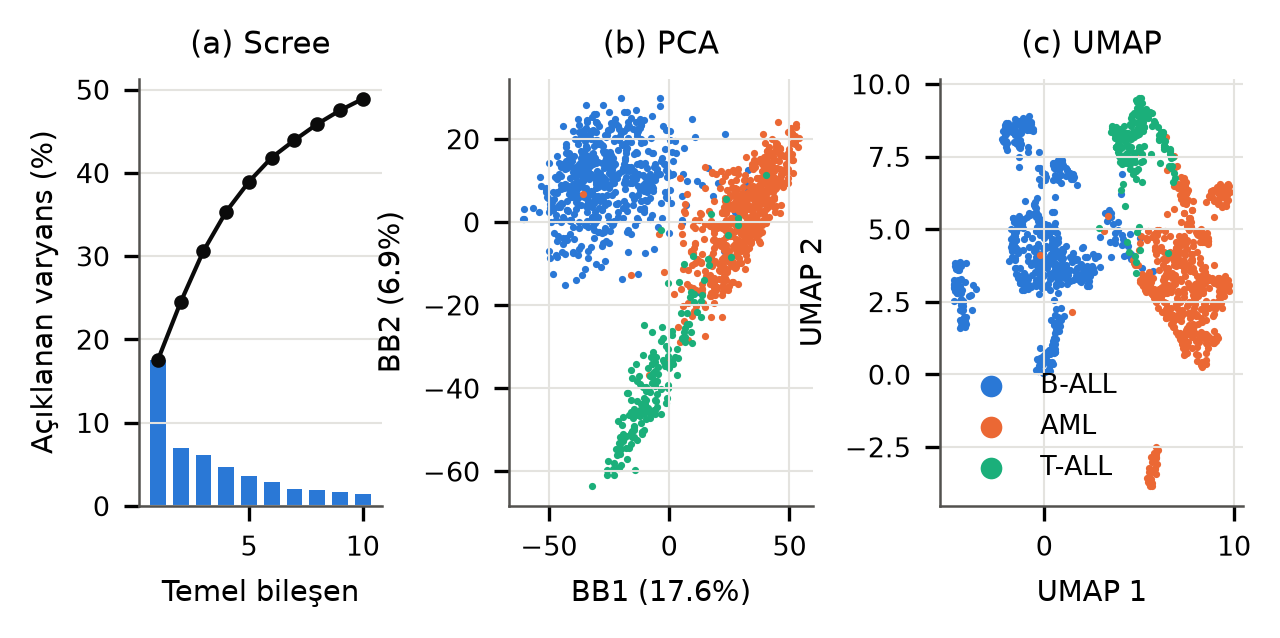

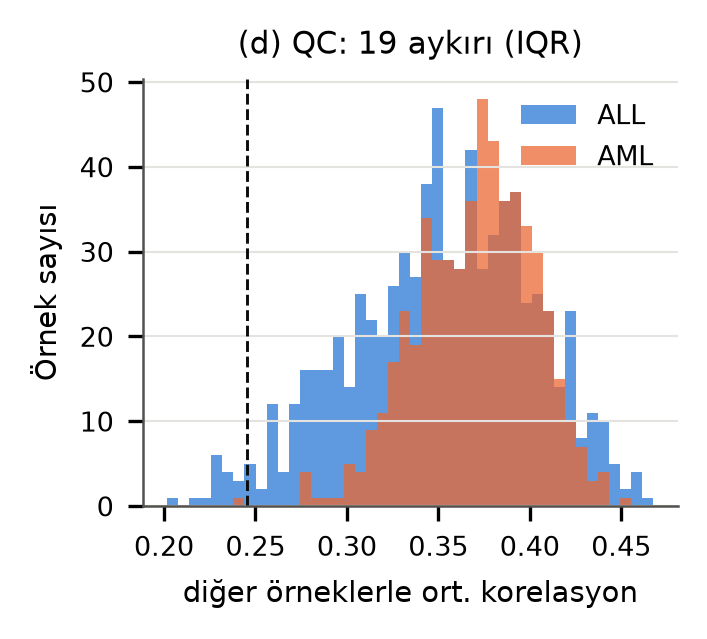

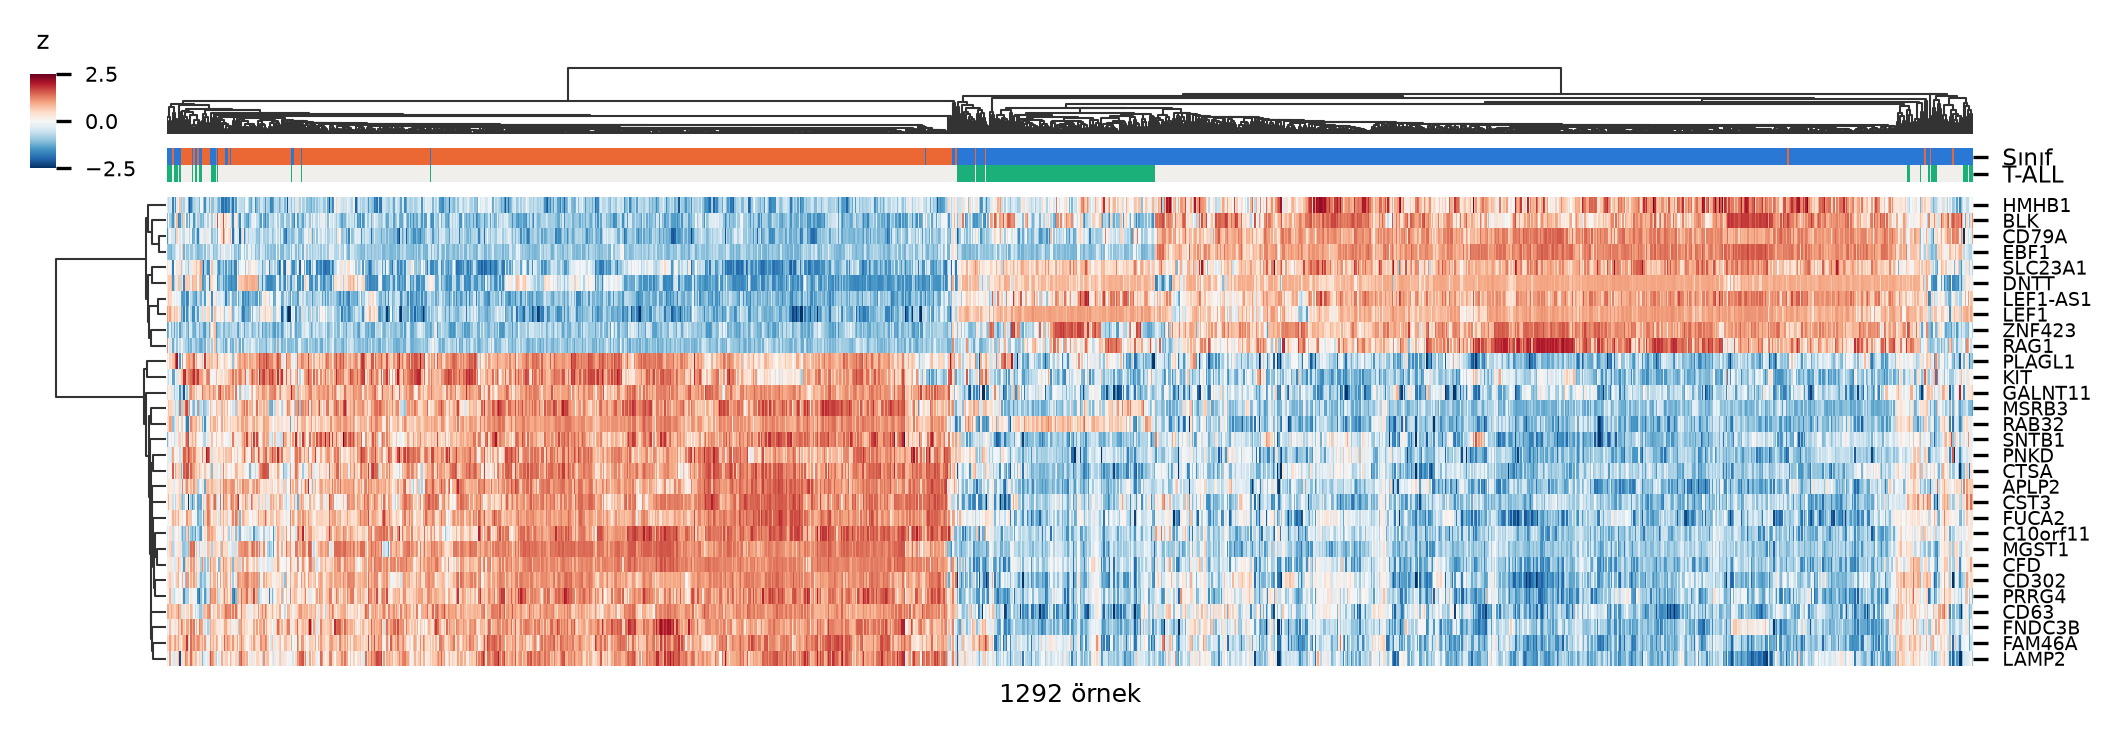

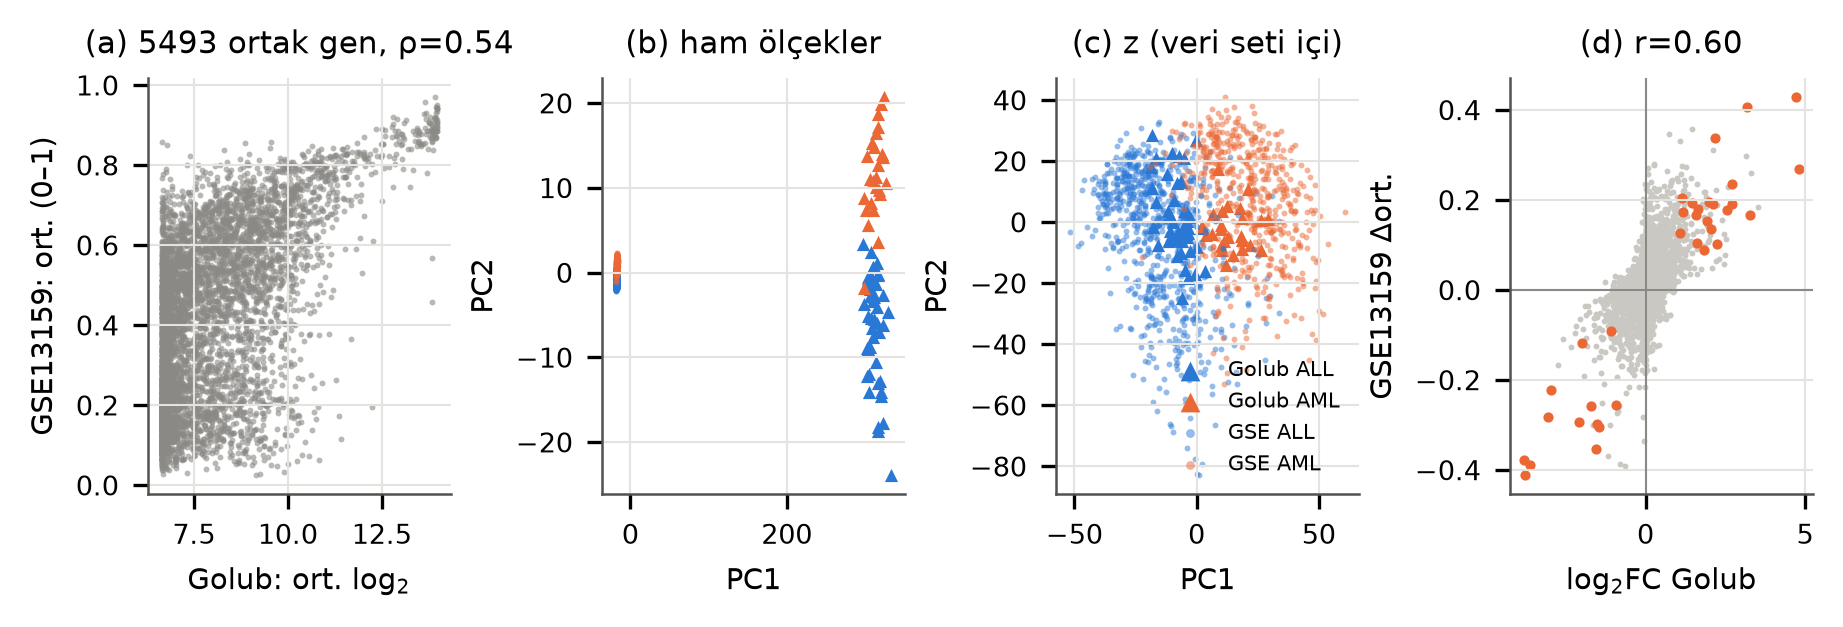

In [10]:
from IPython.display import Image, display
display(Image('results/figures/tr/gse_pca_umap.png', width=900))
display(Image('results/figures/tr/gse_qc_corr.png', width=900))
display(Image('results/figures/tr/gse_heatmap_top30.png', width=900))
display(Image('results/figures/tr/cross_dataset.png', width=900))

## Rapordaki sayılarla karşılaştırma
Bu defterin ürettiği sonuçlardan rapor makroları yeniden hesaplanır ve depodaki `report/numbers.tex` ile karşılaştırılır. Tüm satırlar eşleşiyorsa rapordaki her sayı bu defterle yeniden üretilmiş demektir.

In [11]:
import re, shutil, subprocess
shutil.copy('report/numbers.tex', '/tmp/numbers_rapor.tex')
subprocess.run([sys.executable, 'src/make_macros.py'], check=True, capture_output=True)
oku = lambda p: dict(re.findall(r'\\newcommand\{\\(\w+)\}\{(.*)\}', open(p, encoding='utf-8').read()))
rapor, yeni = oku('/tmp/numbers_rapor.tex'), oku('report/numbers.tex')
anahtar = [k for k in rapor if k.startswith('S')]
fark = [(k, rapor[k], yeni.get(k)) for k in anahtar if rapor[k] != yeni.get(k)]
print(f'GSE13159: {len(anahtar)} sayı karşılaştırıldı, {len(fark)} fark')
for k, a, b in fark: print(f'  {k}: rapor={a}  defter={b}')
print('✓ Rapordaki tüm sayılar eşleşiyor' if not fark else '✗ Farklı sayılar var')
shutil.copy('/tmp/numbers_rapor.tex', 'report/numbers.tex')  # depodaki dosyayı değiştirme

GSE13159: 134 sayı karşılaştırıldı, 0 fark
✓ Rapordaki tüm sayılar eşleşiyor


'report/numbers.tex'